# Team AI Eats — Restaurant Turnover Prediction

**Objective:** Predict annual restaurant turnover in INR and minimize RMSE on unseen restaurants.

**Workflow:** Business goal → Data validation → EDA → Cleaning and feature engineering → Leakage-safe experiments → Tuning → Diagnostics → Result logging → Final submission

## 1. Environment and reproducibility

XGBoost, LightGBM, CatBoost, and statsmodels are optional. Missing packages are reported and unavailable models are skipped. Install them with `pip install xgboost lightgbm catboost statsmodels`.

In [1]:
import importlib
import os
import random
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_SEED = 42
TARGET_COLUMN = "Annual Turnover"
ID_COLUMN = "Registration Number"
DATE_COLUMN = "Opening Day of Restaurant"
REFERENCE_DATE = pd.Timestamp("2016-05-22")
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

os.environ["PYTHONHASHSEED"] = str(RANDOM_SEED)
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 120})

optional_packages = {}
for package_name in ["xgboost", "lightgbm", "catboost", "statsmodels"]:
    try:
        optional_packages[package_name] = importlib.import_module(package_name)
        print(f"Available: {package_name}")
    except ModuleNotFoundError:
        optional_packages[package_name] = None
        print(f"Not installed (related models will be skipped): {package_name}")
print(f"Reproducible environment configured with seed {RANDOM_SEED}.")

Not installed (related models will be skipped): xgboost
Not installed (related models will be skipped): lightgbm
Not installed (related models will be skipped): catboost
Available: statsmodels
Reproducible environment configured with seed 42.


## 2. Business and modeling guardrails

- Target: `Annual Turnover` in INR; primary metric: original-scale RMSE.
- Test data is never used for model or hyperparameter selection.
- Learned preprocessing remains inside CV pipelines.
- `Registration Number` is retained only for submission.
- A log target is selected only if it improves original-scale CV RMSE.

## 3. Load train, test, dictionary, and sample submission

In [2]:
def find_project_root():
    for candidate in [Path.cwd(), Path.cwd() / "Hackathon", Path.cwd().parent]:
        if (candidate / "Train_dataset.csv").exists():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the Hackathon project directory.")

PROJECT_ROOT = find_project_root()
train_raw = pd.read_csv(PROJECT_ROOT / "Train_dataset.csv", na_values=["NA", "N/A", ""])
test_raw = pd.read_csv(PROJECT_ROOT / "Test_dataset.csv", na_values=["NA", "N/A", ""])
data_dictionary = pd.read_csv(PROJECT_ROOT / "Data_Dictionary.csv")
sample_submission = pd.read_csv(PROJECT_ROOT / "Sample_Solution.csv")
print(f"Project root: {PROJECT_ROOT}")
print(f"Train shape: {train_raw.shape}; test shape: {test_raw.shape}")
display(train_raw.head(3), data_dictionary.head(), sample_submission.head())

Project root: C:\Users\vrush\OneDrive\Documents\Artificial Intelligence\PGP - AI and ML for Business Solutions\Hackathon
Train shape: (3493, 34); test shape: (500, 33)


,Registration Number,Annual Turnover,Cuisine,City,Restaurant Location,Opening Day of Restaurant,Facebook Popularity Quotient,Endorsed By,Instagram Popularity Quotient,Fire Audit,Liquor License Obtained,Situated in a Multi Complex,Dedicated Parking,Open Sitting Available,Resturant Tier,Restaurant Type,Restaurant Theme,Restaurant Zomato Rating,Restaurant City Tier,Order Wait Time,Staff Responsivness,Value for Money,Hygiene Rating,Food Rating,Overall Restaurant Rating,Live Music Rating,Comedy Gigs Rating,Value Deals Rating,Live Sports Rating,Ambience,Lively,Service,Comfortablility,Privacy
0,60001,42000000,"indian,irish",Bangalore,Near Business Hub,14-02-2009,84.300,Not Specific,95.800,1,1,1,0,1,2.000,Bar,Arabian,3,0,2,5,5,5,7,10.000,4.000,NaN,NaN,NaN,8.000,8,6,6,6
1,60002,50000000,"indian,irish",Indore,Near Party Hub,29-09-2008,85.400,Tier A Celebrity,85.000,1,1,1,1,0,2.000,Bar,Greek,3,0,6,6,6,7,8,9.000,NaN,4.000,NaN,NaN,5.000,7,7,3,8
2,60003,32500000,"tibetan,italian",Chennai,Near Business Hub,30-07-2011,85.000,Tier A Celebrity,68.200,1,1,1,1,0,2.000,Bar,90's,3,0,2,6,5,3,7,8.000,3.000,NaN,NaN,NaN,7.000,10,5,2,8


,S No.,Variable Name,Variable Description
0,1,Registration Number,This is a restaurant ID
1,2,Annual Turnover,Annual revenue of the restaurant in INR
2,3,Cuisine,Type of cuisine served in the restaurant
3,4,City,City at which the restaurant is located
4,5,Restaurant Location,This variable determines whether the restauran...


,Registration Number,Annual Turnover
0,20001,25000000
1,20002,25000000
2,20003,25000000
3,20004,25000000
4,20005,25000000


## 4. Data-quality audit

Check structure, missingness, duplicates, cardinality, identifier integrity, schema differences, and categorical levels.

In [3]:
def dataset_overview(df, name="Dataset"):
    audit = pd.DataFrame({
        "dtype": df.dtypes.astype(str), "non_null": df.notna().sum(),
        "missing": df.isna().sum(), "missing_pct": df.isna().mean().mul(100),
        "unique": df.nunique(dropna=True),
    }).sort_values(["missing", "unique"], ascending=[False, False])
    audit.index.name = "column"
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]:,} columns")
    print(f"Duplicates: {df.duplicated().sum():,}; missing cells: {df.isna().sum().sum():,}")
    display(audit, df.describe(include="all").T)
    return audit

def categorical_summary(df):
    columns = df.select_dtypes(include=["object", "category", "bool"]).columns
    return pd.DataFrame({
        "unique": df[columns].nunique(dropna=True),
        "missing": df[columns].isna().sum(),
        "sample_values": [df[c].dropna().astype(str).unique()[:6].tolist() for c in columns],
    }).sort_values("unique", ascending=False)

train_audit = dataset_overview(train_raw, "Training data")
test_audit = dataset_overview(test_raw, "Test data")
display(categorical_summary(train_raw), categorical_summary(test_raw))
assert train_raw[ID_COLUMN].is_unique and test_raw[ID_COLUMN].is_unique
assert TARGET_COLUMN in train_raw and TARGET_COLUMN not in test_raw
train_features = set(train_raw.columns) - {TARGET_COLUMN}
test_features = set(test_raw.columns)
print("Train-only feature names:", sorted(train_features - test_features))
print("Test-only feature names:", sorted(test_features - train_features))

Training data: 3,493 rows × 34 columns
Duplicates: 0; missing cells: 9,684


,dtype,non_null,missing,missing_pct,unique
column,,,,,
Live Sports Rating,float64,205,3288,94.131,5
Value Deals Rating,float64,786,2707,77.498,7
Comedy Gigs Rating,float64,1010,2483,71.085,6
Live Music Rating,float64,2728,765,21.901,8
Overall Restaurant Rating,float64,3281,212,6.069,5
Facebook Popularity Quotient,float64,3394,99,2.834,776
Instagram Popularity Quotient,float64,3437,56,1.603,742
Resturant Tier,float64,3444,49,1.403,2
Ambience,float64,3468,25,0.716,11


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Registration Number,"3,493.000",NaN,NaN,NaN,"61,747.000","1,008.487","60,001.000","60,874.000","61,747.000","62,620.000","63,493.000"
Annual Turnover,"3,493.000",NaN,NaN,NaN,"30,725,708.560","21,651,246.901","3,500,000.000","18,000,000.000","30,000,000.000","37,000,000.000","400,000,000.000"
Cuisine,3493,20,"tibetan,greek",686,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,3493,297,Bangalore,553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Restaurant Location,3493,2,Near Party Hub,2658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opening Day of Restaurant,3493,1778,27-12-2009,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Facebook Popularity Quotient,"3,394.000",NaN,NaN,NaN,77.939,9.829,43.000,72.000,79.000,85.745,97.760
Endorsed By,3493,3,Not Specific,1961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Instagram Popularity Quotient,"3,437.000",NaN,NaN,NaN,74.405,10.940,40.000,66.000,74.050,82.400,98.700
Fire Audit,"3,493.000",NaN,NaN,NaN,0.789,0.408,0.000,1.000,1.000,1.000,1.000


Test data: 500 rows × 33 columns
Duplicates: 0; missing cells: 1,362


,dtype,non_null,missing,missing_pct,unique
column,,,,,
Live Sports Rating,float64,29,471,94.200,5
Value Deals Rating,float64,115,385,77.000,5
Comedy Gigs Rating,float64,130,370,74.000,6
Live Music Rating,float64,398,102,20.400,7
Overall Restaurant Rating,float64,466,34,6.800,5
Registration Number,int64,500,0,0.000,500
Opening Day of Restaurant,object,500,0,0.000,437
Facebook Popularity Quotient,float64,500,0,0.000,275
Instagram Popularity Quotient,float64,500,0,0.000,253


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Registration Number,500.000,NaN,NaN,NaN,"20,250.500",144.482,"20,001.000","20,125.750","20,250.500","20,375.250","20,500.000"
Cuisine,500,20,"tibetan,greek",115,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,500,97,Bangalore,74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Restaurant Location,500,2,Near Party Hub,378,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Opening Day of Restaurant,500,437,10-03-2010,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Facebook Popularity Quotient,500.000,NaN,NaN,NaN,77.541,10.084,46.000,70.575,79.000,85.233,96.800
Endoresed By,500,3,Not Specific,299,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Instagram Popularity Quotient,500.000,NaN,NaN,NaN,74.753,11.337,47.000,65.915,75.000,83.600,97.200
Fire Audit,500.000,NaN,NaN,NaN,0.814,0.389,0.000,1.000,1.000,1.000,1.000
Liquor License Obtained,500.000,NaN,NaN,NaN,0.986,0.118,0.000,1.000,1.000,1.000,1.000


,unique,missing,sample_values
Opening Day of Restaurant,1778,0,"[14-02-2009, 29-09-2008, 30-07-2011, 30-11-200..."
City,297,0,"[Bangalore, Indore, Chennai, Gurgaon, Manesar,..."
Restaurant Theme,34,0,"[Arabian, Greek, 90's, Nature, Parsi, English]"
Cuisine,20,0,"[indian,irish, tibetan,italian, turkish,nigeri..."
Restaurant Type,4,0,"[Bar, Caffee, Gastro Bar, Buffet/Family Restau..."
Endorsed By,3,0,"[Not Specific, Tier A Celebrity, Local Celebrity]"
Restaurant Location,2,0,"[Near Business Hub, Near Party Hub]"


,unique,missing,sample_values
Opening Day of Restaurant,437,0,"[13-07-2010, 05-09-2011, 12-04-2011, 16-01-200..."
City,97,0,"[Bangalore, Hyderabad, -1, Pune , New Delhi, M..."
Cuisine,20,0,"[tibetan,italian, algerian,belgian, tibetan,gr..."
Restaurant Theme,18,0,"[Greek, Nature, 90's, Mise En, Arabian, Molino]"
Restaurant Type,4,0,"[Bar, Gastro Bar, Caffee, Buffet/Family Restau..."
Endoresed By,3,0,"[Tier A Celebrity, Not Specific, Local Celebrity]"
Restaurant Location,2,0,"[Near Business Hub, Near Party Hub]"


Train-only feature names: ['Endorsed By']
Test-only feature names: ['Endoresed By']


## 5. Target distribution and transformation decision

Skewness motivates a candidate transformation but does not decide it. Original and `log1p` targets are compared using identical folds and original-scale RMSE.

,Annual Turnover
count,"3,493.000"
mean,"30,725,708.560"
std,"21,651,246.901"
min,"3,500,000.000"
1%,"7,000,000.000"
5%,"10,000,000.000"
25%,"18,000,000.000"
50%,"30,000,000.000"
75%,"37,000,000.000"
95%,"57,000,000.000"


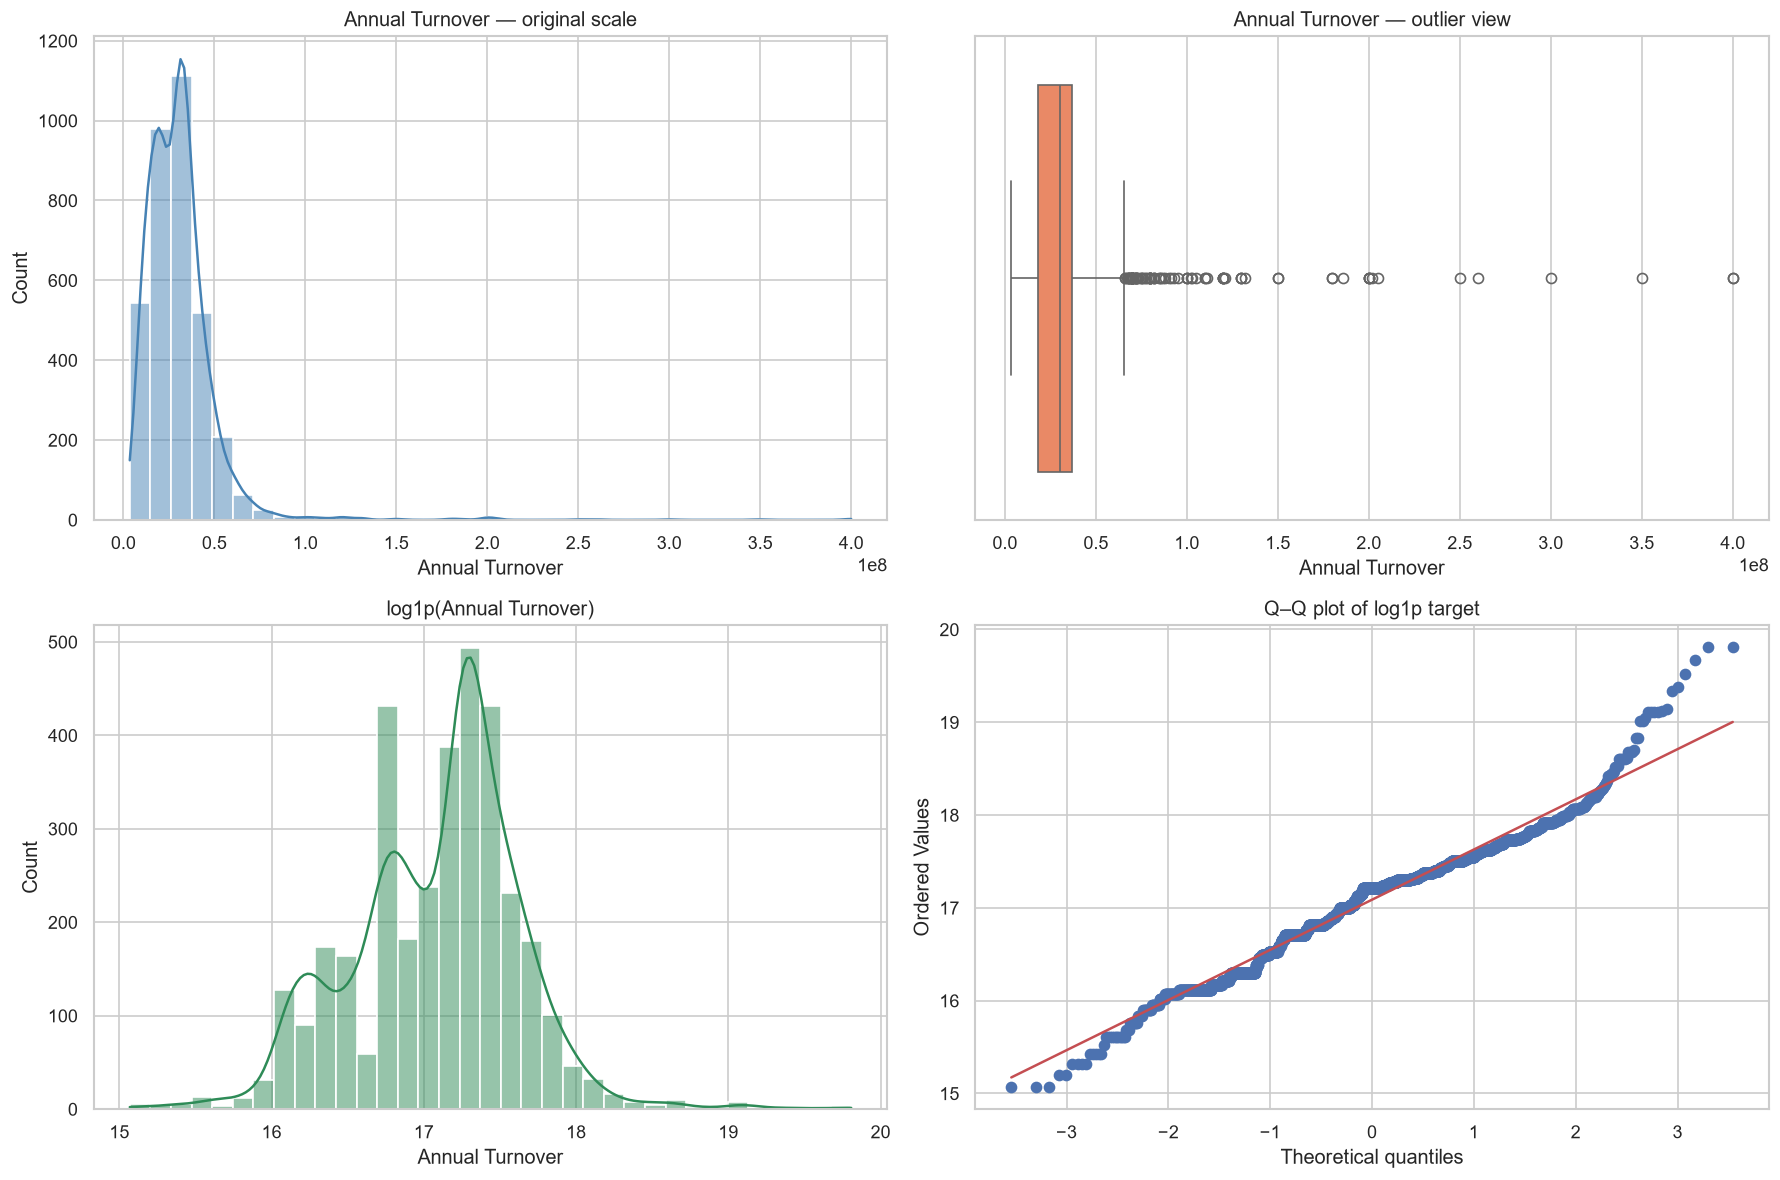

Original skew: 6.653; log1p skew: -0.096


In [4]:
target = pd.to_numeric(train_raw[TARGET_COLUMN], errors="coerce")
assert target.notna().all() and (target >= 0).all()
target_report = target.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame()
target_report.loc["skewness"] = target.skew()
target_report.loc["kurtosis"] = target.kurtosis()
display(target_report)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(target, bins=35, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Annual Turnover — original scale")
sns.boxplot(x=target, ax=axes[0, 1], color="coral")
axes[0, 1].set_title("Annual Turnover — outlier view")
sns.histplot(np.log1p(target), bins=35, kde=True, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("log1p(Annual Turnover)")
stats.probplot(np.log1p(target), dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q–Q plot of log1p target")
plt.tight_layout(); plt.show()
print(f"Original skew: {target.skew():.3f}; log1p skew: {np.log1p(target).skew():.3f}")

## 6. Deterministic cleaning and feature engineering

City aliases are explicit and reviewable. Dates use a fixed reference date. Learned imputation, scaling, infrequent-category grouping, and encoding remain inside model pipelines.

In [5]:
CITY_ALIASES = {
    "banglore": "Bangalore", "banagalore": "Bangalore", "banaglore": "Bangalore",
    "bengaluru": "Bangalore", "asifabadbanglore": "Bangalore",
    "gurgoan": "Gurgaon", "guragaon": "Gurgaon", "gurga": "Gurgaon",
    "new dehli": "New Delhi", "nouda": "Noida",
    "bhubaneshwar": "Bhubaneswar", "bhubneshwar": "Bhubaneswar",
    "gajiabaad": "Ghaziabad", "gaziabaad": "Ghaziabad", "shahibabad": "Ghaziabad",
    "vizag": "Visakhapatnam", "vsakhapttnam": "Visakhapatnam",
    "hderabad": "Hyderabad", "hyderabad(bhadurpally)": "Hyderabad",
    "trivandrum": "Thiruvananthapuram", "technopark, trivandrum": "Thiruvananthapuram",
    "kochi/cochin": "Kochi", "ernakulam": "Kochi", "baroda": "Vadodara",
    "pondy": "Pondicherry", "pondi": "Pondicherry", "sonepat": "Sonipat",
    "punchkula": "Panchkula", "nasikcity": "Nashik", "trichy": "Tiruchirappalli",
    "trichur": "Thrissur", "calicut": "Kozhikode", "hissar": "Hisar",
    "muzzafarpur": "Muzaffarpur", "bareli": "Bareilly",
}
INVALID_CITY_VALUES = {"", "-1", "am", "india", "ncr"}
RATING_COLUMNS = [
    "Restaurant Zomato Rating", "Order Wait Time", "Staff Responsivness", "Value for Money",
    "Hygiene Rating", "Food Rating", "Overall Restaurant Rating", "Live Music Rating",
    "Comedy Gigs Rating", "Value Deals Rating", "Live Sports Rating", "Ambience",
    "Lively", "Service", "Comfortablility", "Privacy",
]
FACILITY_COLUMNS = ["Fire Audit", "Liquor License Obtained", "Situated in a Multi Complex", "Dedicated Parking", "Open Sitting Available"]

def normalize_city(value):
    if pd.isna(value):
        return "Unknown"
    cleaned = " ".join(str(value).strip().lower().replace("`", "").split())
    if cleaned in INVALID_CITY_VALUES:
        return "Unknown"
    return CITY_ALIASES.get(cleaned, cleaned.title())

def engineer_features(df):
    result = df.copy().rename(columns={"Endoresed By": "Endorsed By"})
    raw_city = result["City"].copy()
    result["City"] = raw_city.map(normalize_city)
    result["City Was Corrected"] = (raw_city.fillna("Unknown").astype(str).str.strip().str.title() != result["City"]).astype(int)
    opened = pd.to_datetime(result[DATE_COLUMN], format="%d-%m-%Y", errors="coerce")
    result["Restaurant Age Days"] = (REFERENCE_DATE - opened).dt.days.clip(lower=0)
    result["Restaurant Age Years"] = result["Restaurant Age Days"] / 365.25
    result["Opening Year"] = opened.dt.year
    result["Opening Month"] = opened.dt.month
    result["Opening Quarter"] = opened.dt.quarter
    result["Opening Day of Week"] = opened.dt.dayofweek
    result = result.drop(columns=DATE_COLUMN)
    result["Social Popularity Mean"] = result[["Facebook Popularity Quotient", "Instagram Popularity Quotient"]].mean(axis=1)
    ratings = [c for c in RATING_COLUMNS if c in result]
    result["Customer Rating Mean"] = result[ratings].mean(axis=1)
    result["Customer Rating Missing Count"] = result[ratings].isna().sum(axis=1)
    facilities = [c for c in FACILITY_COLUMNS if c in result]
    result["Facility Count"] = result[facilities].sum(axis=1, min_count=1)
    result["Cuisine Count"] = result["Cuisine"].fillna("").str.count(",") + 1
    return result

train_clean = engineer_features(train_raw)
test_clean = engineer_features(test_raw)
test_clean = test_clean.reindex(columns=[c for c in train_clean.columns if c != TARGET_COLUMN])
print(f"City cardinality: {train_raw['City'].nunique()} raw → {train_clean['City'].nunique()} normalized")
print(f"Missing parsed dates — train: {train_clean['Restaurant Age Years'].isna().sum()}, test: {test_clean['Restaurant Age Years'].isna().sum()}")

City cardinality: 297 raw → 174 normalized
Missing parsed dates — train: 0, test: 0


## 7. Post-cleaning validation and focused EDA

,raw_unique,clean_unique,unknown_rows
train,297,174,399
test,97,68,65


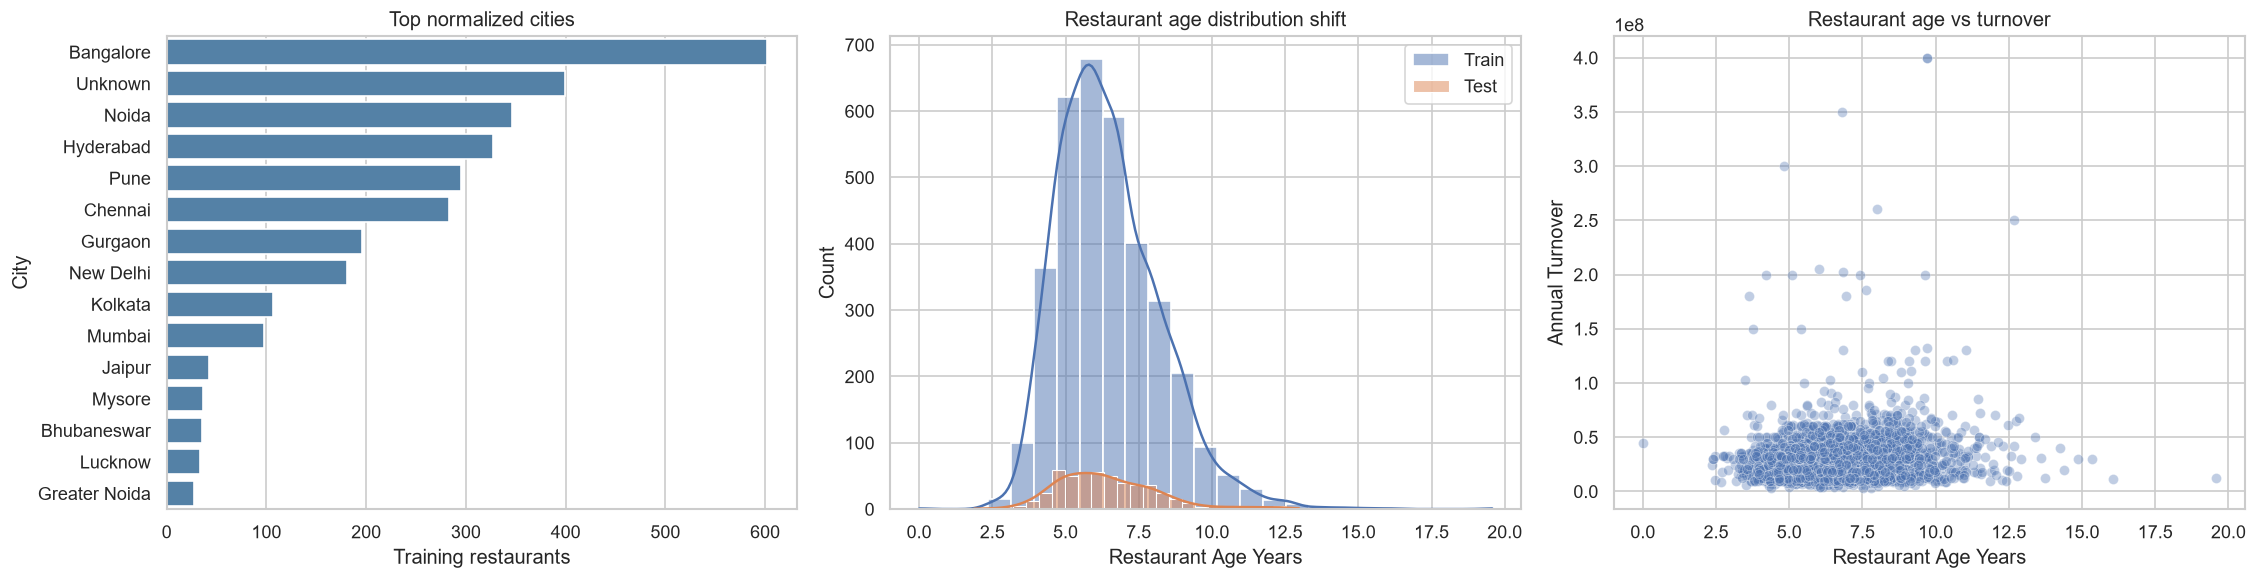

Age/turnover Spearman correlation: 0.147


In [6]:
assert list(test_clean.columns) == [c for c in train_clean.columns if c != TARGET_COLUMN]
assert train_clean[ID_COLUMN].is_unique and test_clean[ID_COLUMN].is_unique
assert train_clean["Restaurant Age Years"].ge(0).all()
city_quality = pd.DataFrame({
    "raw_unique": [train_raw["City"].nunique(), test_raw["City"].nunique()],
    "clean_unique": [train_clean["City"].nunique(), test_clean["City"].nunique()],
    "unknown_rows": [train_clean["City"].eq("Unknown").sum(), test_clean["City"].eq("Unknown").sum()],
}, index=["train", "test"])
display(city_quality)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
top_cities = train_clean["City"].value_counts().head(15)
sns.barplot(x=top_cities.values, y=top_cities.index, ax=axes[0], color="steelblue")
axes[0].set(title="Top normalized cities", xlabel="Training restaurants")
sns.histplot(train_clean["Restaurant Age Years"], bins=25, kde=True, ax=axes[1], label="Train")
sns.histplot(test_clean["Restaurant Age Years"], bins=25, kde=True, ax=axes[1], label="Test", alpha=0.5)
axes[1].set_title("Restaurant age distribution shift"); axes[1].legend()
sns.scatterplot(data=train_clean, x="Restaurant Age Years", y=TARGET_COLUMN, alpha=0.35, ax=axes[2])
axes[2].set_title("Restaurant age vs turnover")
plt.tight_layout(); plt.show()
age_spearman = train_clean[["Restaurant Age Years", TARGET_COLUMN]].corr(method="spearman").iloc[0, 1]
print(f"Age/turnover Spearman correlation: {age_spearman:.3f}")

## 8. Modeling matrix and leakage-safe preprocessing

Deterministic cleaning is complete. Imputation, scaling, infrequent-category grouping, and one-hot encoding are fitted within each CV fold.

In [7]:
test_ids = test_clean[ID_COLUMN].copy().reset_index(drop=True)
X = train_clean.drop(columns=[TARGET_COLUMN, ID_COLUMN])
y = train_clean[TARGET_COLUMN].astype(float)
X_test = test_clean.drop(columns=ID_COLUMN).reindex(columns=X.columns)
numeric_columns = X.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=5)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns),
])
print(f"Model matrix: {X.shape}; numeric={len(numeric_columns)}, categorical={len(categorical_columns)}")

Model matrix: (3493, 43); numeric=37, categorical=6


## 9. Candidate models

Mean baseline, Linear Regression, Ridge, Random Forest, Extra Trees, XGBoost, LightGBM, and CatBoost are considered. Optional models appear only when installed.

In [8]:
models = {
    "Mean Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=350, min_samples_leaf=2, max_features=0.8, n_jobs=-1, random_state=RANDOM_SEED),
    "Extra Trees": ExtraTreesRegressor(n_estimators=350, min_samples_leaf=2, max_features=0.9, n_jobs=-1, random_state=RANDOM_SEED),
}
if optional_packages["xgboost"] is not None:
    models["XGBoost"] = optional_packages["xgboost"].XGBRegressor(
        objective="reg:squarederror", n_estimators=500, learning_rate=0.03, max_depth=5,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=5.0, n_jobs=-1, random_state=RANDOM_SEED)
if optional_packages["lightgbm"] is not None:
    models["LightGBM"] = optional_packages["lightgbm"].LGBMRegressor(
        objective="regression", n_estimators=500, learning_rate=0.03, num_leaves=31,
        min_child_samples=20, colsample_bytree=0.85, reg_lambda=5.0, verbosity=-1, n_jobs=-1, random_state=RANDOM_SEED)
if optional_packages["catboost"] is not None:
    models["CatBoost"] = optional_packages["catboost"].CatBoostRegressor(
        iterations=500, learning_rate=0.03, depth=7, loss_function="RMSE",
        verbose=0, allow_writing_files=False, random_seed=RANDOM_SEED)
print("Models included:", list(models))

Models included: ['Mean Baseline', 'Linear Regression', 'Ridge', 'Random Forest', 'Extra Trees']


## 10. Cross-validated experiments and result logging

Every non-baseline model is tested with original and log-transformed targets. All metrics are evaluated in original INR units.

In [9]:
experiment_rows = []
experiment_estimators = {}

def make_estimator(model, target_scale="original"):
    pipeline = Pipeline([("preprocessing", clone(preprocessor)), ("model", clone(model))])
    if target_scale == "log1p":
        return TransformedTargetRegressor(regressor=pipeline, func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    return pipeline

def evaluate_model(model_name, model, target_scale):
    estimator = make_estimator(model, target_scale)
    scores = cross_validate(estimator, X, y, cv=CV, scoring=SCORING, n_jobs=1, return_train_score=False)
    row = {
        "model": model_name, "target_scale": target_scale,
        "mean_rmse": -scores["test_rmse"].mean(), "std_rmse": scores["test_rmse"].std(),
        "mean_mae": -scores["test_mae"].mean(), "mean_r2": scores["test_r2"].mean(),
        "fit_seconds": scores["fit_time"].sum(), "fold_rmse": (-scores["test_rmse"]).round(2).tolist(),
    }
    experiment_rows.append(row)
    experiment_estimators[(model_name, target_scale)] = estimator
    print(f"{model_name:20s} | {target_scale:8s} | RMSE {row['mean_rmse']:,.0f} ± {row['std_rmse']:,.0f}")

for model_name, model in models.items():
    for target_scale in (["original"] if model_name == "Mean Baseline" else ["original", "log1p"]):
        evaluate_model(model_name, model, target_scale)
experiment_results = pd.DataFrame(experiment_rows).sort_values("mean_rmse").reset_index(drop=True)
display(experiment_results.drop(columns="fold_rmse"))
results_path = PROJECT_ROOT / "experiments" / "notebook_experiment_results.csv"
results_path.parent.mkdir(exist_ok=True)
experiment_results.to_csv(results_path, index=False)
print(f"Saved experiment log: {results_path}")

Mean Baseline        | original | RMSE 21,510,493 ± 2,490,428
Linear Regression    | original | RMSE 20,111,232 ± 2,639,402
Linear Regression    | log1p    | RMSE 20,201,637 ± 2,746,239
Ridge                | original | RMSE 20,007,759 ± 2,640,153
Ridge                | log1p    | RMSE 20,145,324 ± 2,746,734
Random Forest        | original | RMSE 20,157,311 ± 2,593,973
Random Forest        | log1p    | RMSE 20,287,084 ± 2,722,561
Extra Trees          | original | RMSE 20,079,457 ± 2,673,948
Extra Trees          | log1p    | RMSE 20,163,955 ± 2,770,559


,model,target_scale,mean_rmse,std_rmse,mean_mae,mean_r2,fit_seconds
0,Ridge,original,"20,007,759.456","2,640,153.260","10,695,019.444",0.135,0.141
1,Extra Trees,original,"20,079,456.949","2,673,947.697","10,679,198.041",0.129,7.777
2,Linear Regression,original,"20,111,232.403","2,639,401.799","10,793,491.249",0.126,0.316
3,Ridge,log1p,"20,145,324.209","2,746,734.337","10,298,039.259",0.124,0.184
4,Random Forest,original,"20,157,310.876","2,593,973.013","10,786,066.527",0.122,9.742
5,Extra Trees,log1p,"20,163,954.670","2,770,559.294","10,255,273.074",0.123,7.789
6,Linear Regression,log1p,"20,201,637.157","2,746,239.226","10,340,922.186",0.119,0.290
7,Random Forest,log1p,"20,287,083.549","2,722,560.848","10,427,151.272",0.112,7.137
8,Mean Baseline,original,"21,510,492.759","2,490,427.612","12,315,384.342",-0.002,0.264


Saved experiment log: C:\Users\vrush\OneDrive\Documents\Artificial Intelligence\PGP - AI and ML for Business Solutions\Hackathon\experiments\notebook_experiment_results.csv


## 11. Experiment observations

After execution, record which model wins, whether `log1p` helps, CV stability, runtime trade-offs, and whether engineered features justify their complexity.

In [10]:
best_by_model = experiment_results.loc[
    experiment_results.groupby("model")["mean_rmse"].idxmin(),
    ["model", "target_scale", "mean_rmse", "std_rmse", "mean_r2"],
].sort_values("mean_rmse")
display(best_by_model)
best_row = experiment_results.iloc[0]
baseline_rmse = experiment_results.loc[experiment_results["model"].eq("Mean Baseline"), "mean_rmse"].iloc[0]
improvement = 100 * (baseline_rmse - best_row["mean_rmse"]) / baseline_rmse
print(f"Best: {best_row['model']} ({best_row['target_scale']}); RMSE {best_row['mean_rmse']:,.0f} ± {best_row['std_rmse']:,.0f}")
print(f"Improvement over mean baseline: {improvement:.2f}%")
pivot = experiment_results.pivot(index="model", columns="target_scale", values="mean_rmse")
if {"original", "log1p"}.issubset(pivot.columns):
    pivot["log1p_improvement_pct"] = 100 * (pivot["original"] - pivot["log1p"]) / pivot["original"]
display(pivot)

,model,target_scale,mean_rmse,std_rmse,mean_r2
0,Ridge,original,"20,007,759.456","2,640,153.260",0.135
1,Extra Trees,original,"20,079,456.949","2,673,947.697",0.129
2,Linear Regression,original,"20,111,232.403","2,639,401.799",0.126
4,Random Forest,original,"20,157,310.876","2,593,973.013",0.122
8,Mean Baseline,original,"21,510,492.759","2,490,427.612",-0.002


Best: Ridge (original); RMSE 20,007,759 ± 2,640,153
Improvement over mean baseline: 6.99%


target_scale,log1p,original,log1p_improvement_pct
model,,,
Extra Trees,"20,163,954.670","20,079,456.949",-0.421
Linear Regression,"20,201,637.157","20,111,232.403",-0.450
Mean Baseline,NaN,"21,510,492.759",NaN
Random Forest,"20,287,083.549","20,157,310.876",-0.644
Ridge,"20,145,324.209","20,007,759.456",-0.688


## 12. Hyperparameter tuning

Tune the best tree/boosting family rather than every model. The winning target scale is preserved.

In [11]:
tunable_names = {"Random Forest", "Extra Trees", "XGBoost", "LightGBM", "CatBoost"}
tuning_row = experiment_results[experiment_results["model"].isin(tunable_names)].iloc[0]
TUNING_MODEL_NAME, TUNING_TARGET_SCALE = tuning_row["model"], tuning_row["target_scale"]
tuning_estimator = experiment_estimators[(TUNING_MODEL_NAME, TUNING_TARGET_SCALE)]
parameter_spaces = {
    "Random Forest": {"model__n_estimators": [300, 500, 750], "model__max_depth": [None, 8, 12, 18], "model__min_samples_leaf": [1, 2, 4, 7], "model__max_features": [0.5, 0.75, 1.0]},
    "Extra Trees": {"model__n_estimators": [300, 500, 750], "model__max_depth": [None, 8, 12, 18], "model__min_samples_leaf": [1, 2, 4, 7], "model__max_features": [0.5, 0.75, 1.0]},
    "XGBoost": {"model__n_estimators": [300, 500, 750], "model__learning_rate": [0.02, 0.03, 0.05, 0.08], "model__max_depth": [3, 4, 5, 7], "model__subsample": [0.7, 0.85, 1.0], "model__colsample_bytree": [0.7, 0.85, 1.0], "model__reg_lambda": [1, 5, 10, 25]},
    "LightGBM": {"model__n_estimators": [300, 500, 750], "model__learning_rate": [0.02, 0.03, 0.05, 0.08], "model__num_leaves": [15, 31, 63], "model__min_child_samples": [10, 20, 40, 60], "model__colsample_bytree": [0.7, 0.85, 1.0], "model__reg_lambda": [1, 5, 10, 25]},
    "CatBoost": {"model__iterations": [300, 500, 750], "model__learning_rate": [0.02, 0.03, 0.05, 0.08], "model__depth": [4, 6, 7, 8, 10], "model__l2_leaf_reg": [1, 3, 5, 10, 20]},
}
search_space = parameter_spaces[TUNING_MODEL_NAME]
if TUNING_TARGET_SCALE == "log1p":
    search_space = {f"regressor__{key}": value for key, value in search_space.items()}
print(f"Tuning {TUNING_MODEL_NAME} with {TUNING_TARGET_SCALE} target...")
tuner = RandomizedSearchCV(
    clone(tuning_estimator), search_space, n_iter=15, scoring="neg_root_mean_squared_error",
    cv=CV, random_state=RANDOM_SEED, n_jobs=1, verbose=1, refit=True, return_train_score=True)
tuner.fit(X, y)
best_estimator = tuner.best_estimator_
print(f"Best tuned CV RMSE: {-tuner.best_score_:,.0f}")
display(pd.Series(tuner.best_params_, name="value").to_frame())

Tuning Extra Trees with original target...
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best tuned CV RMSE: 19,934,814


,value
model__n_estimators,300.000
model__min_samples_leaf,7.000
model__max_features,0.500
model__max_depth,18.000


## 13. Out-of-fold diagnostics and interpretation

For nonlinear ensembles these are predictive diagnostics, not strict linear-regression assumption tests.

,value
OOF RMSE,"20,119,124.147"
OOF MAE,"10,533,200.120"
OOF R²,0.136
Residual mean,"43,791.534"
Residual skewness,7.798


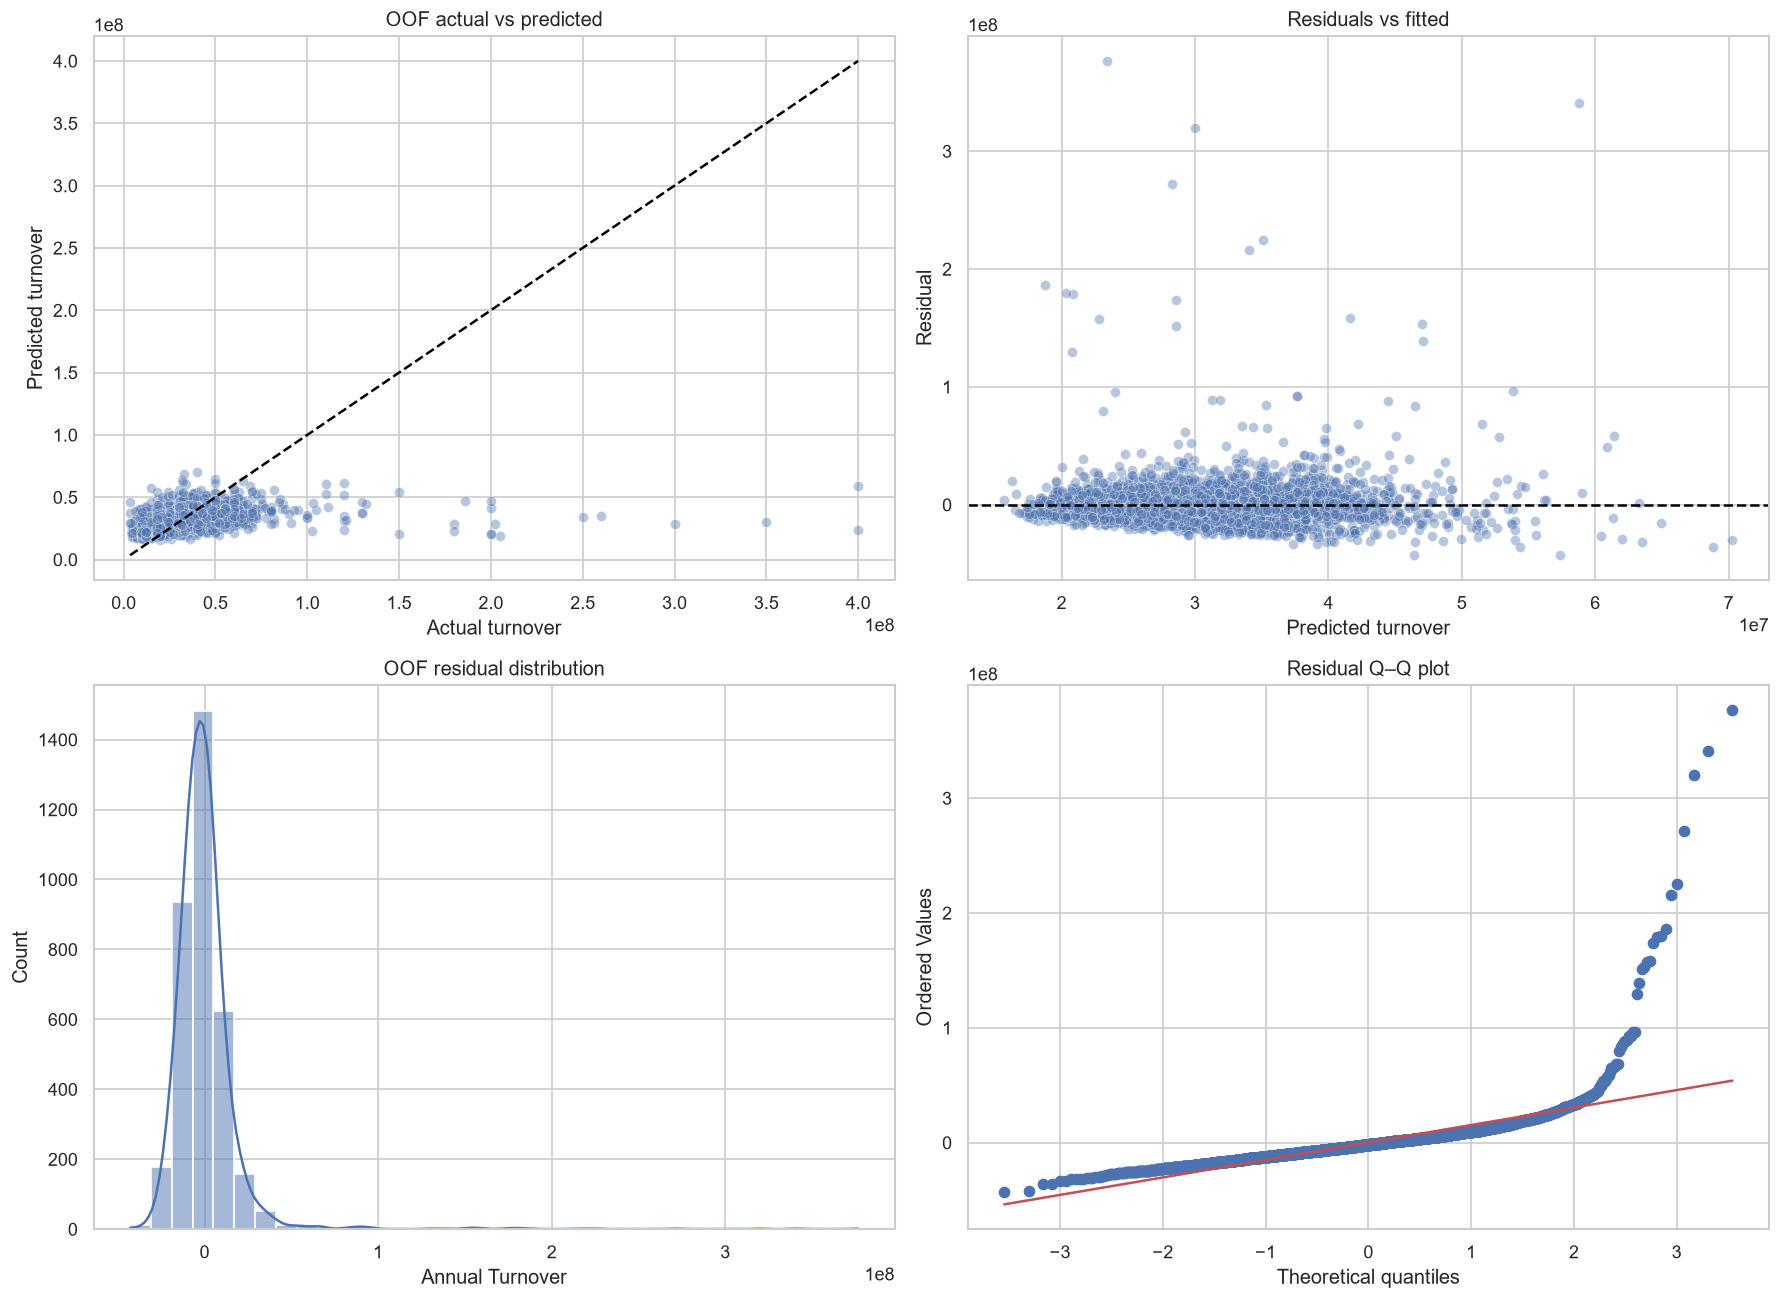

,Registration Number,Annual Turnover,OOF Prediction,Absolute Error
2179,62180,400000000,"23,424,471.959","376,575,528.041"
1237,61238,400000000,"58,791,220.423","341,208,779.577"
779,60780,350000000,"30,004,540.493","319,995,459.507"
1759,61760,300000000,"28,264,880.676","271,735,119.324"
500,60501,260000000,"35,069,265.886","224,930,734.114"
1982,61983,250000000,"34,052,240.411","215,947,759.589"
1517,61518,205000000,"18,748,354.759","186,251,645.241"
3485,63486,200000000,"20,304,608.260","179,695,391.740"
3479,63480,200000000,"20,831,215.878","179,168,784.122"
1239,61240,202000000,"28,567,871.097","173,432,128.903"


In [12]:
oof_predictions = np.clip(cross_val_predict(best_estimator, X, y, cv=CV, n_jobs=1), 0, None)
residuals = y - oof_predictions
display(pd.Series({
    "OOF RMSE": mean_squared_error(y, oof_predictions) ** 0.5,
    "OOF MAE": mean_absolute_error(y, oof_predictions),
    "OOF R²": r2_score(y, oof_predictions),
    "Residual mean": residuals.mean(), "Residual skewness": residuals.skew(),
}, name="value").to_frame())
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
sns.scatterplot(x=y, y=oof_predictions, alpha=0.4, ax=axes[0, 0])
limits = [min(y.min(), oof_predictions.min()), max(y.max(), oof_predictions.max())]
axes[0, 0].plot(limits, limits, "--", color="black")
axes[0, 0].set(title="OOF actual vs predicted", xlabel="Actual turnover", ylabel="Predicted turnover")
sns.scatterplot(x=oof_predictions, y=residuals, alpha=0.4, ax=axes[0, 1])
axes[0, 1].axhline(0, linestyle="--", color="black")
axes[0, 1].set(title="Residuals vs fitted", xlabel="Predicted turnover", ylabel="Residual")
sns.histplot(residuals, bins=35, kde=True, ax=axes[1, 0]); axes[1, 0].set_title("OOF residual distribution")
stats.probplot(residuals, dist="norm", plot=axes[1, 1]); axes[1, 1].set_title("Residual Q–Q plot")
plt.tight_layout(); plt.show()
error_review = train_raw[[ID_COLUMN, TARGET_COLUMN]].copy()
error_review["OOF Prediction"] = oof_predictions
error_review["Absolute Error"] = residuals.abs()
display(error_review.nlargest(15, "Absolute Error"))

,feature,importance,std
11,Resturant Tier,"490,250.463","103,619.812"
19,Hygiene Rating,"289,766.667","43,062.749"
0,Cuisine,"201,666.350","56,150.865"
22,Live Music Rating,"196,944.431","30,061.756"
38,Social Popularity Mean,"179,644.094","30,263.497"
1,City,"169,388.369","46,687.728"
5,Instagram Popularity Quotient,"145,475.551","23,573.310"
8,Situated in a Multi Complex,"141,043.155","33,828.500"
13,Restaurant Theme,"96,720.513","23,155.164"
24,Value Deals Rating,"94,569.279","81,315.076"


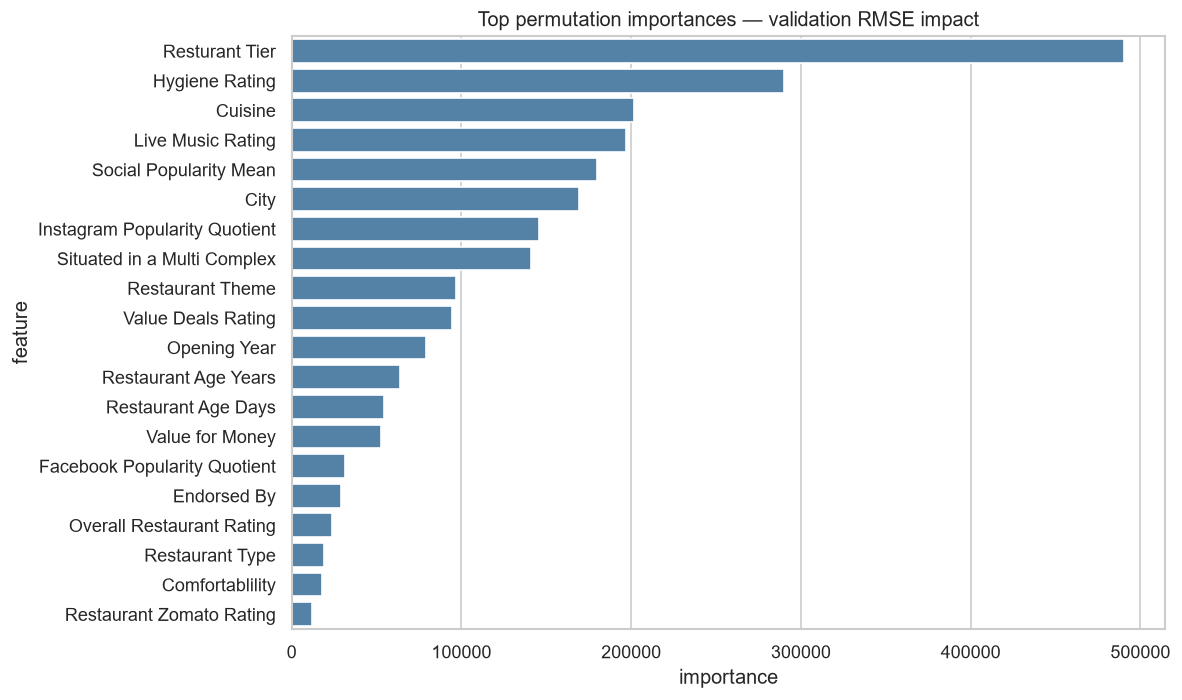

In [13]:
# Model-agnostic importance on raw engineered features; this can take several minutes.
X_train_pi, X_valid_pi, y_train_pi, y_valid_pi = train_test_split(X, y, test_size=0.20, random_state=RANDOM_SEED)
importance_estimator = clone(best_estimator).fit(X_train_pi, y_train_pi)
importance = permutation_importance(
    importance_estimator, X_valid_pi, y_valid_pi, scoring="neg_root_mean_squared_error",
    n_repeats=5, random_state=RANDOM_SEED, n_jobs=1)
importance_df = pd.DataFrame({"feature": X.columns, "importance": importance.importances_mean, "std": importance.importances_std}).sort_values("importance", ascending=False)
display(importance_df.head(20))
sns.barplot(data=importance_df.head(20), x="importance", y="feature", color="steelblue")
plt.title("Top permutation importances — validation RMSE impact"); plt.tight_layout(); plt.show()

## 14. Final refit, persistence, and submission

Refit the tuned pipeline on all training rows and enforce ID order, row count, schema, finite predictions, and non-negative turnover.

In [14]:
final_model = clone(best_estimator).fit(X, y)
test_predictions = np.clip(final_model.predict(X_test), 0, None)
submission = pd.DataFrame({ID_COLUMN: test_ids.to_numpy(), TARGET_COLUMN: test_predictions})
assert submission.shape == (len(test_raw), 2)
assert submission.columns.tolist() == [ID_COLUMN, TARGET_COLUMN]
assert submission[ID_COLUMN].equals(test_raw[ID_COLUMN].reset_index(drop=True))
assert np.isfinite(submission[TARGET_COLUMN]).all() and submission[TARGET_COLUMN].ge(0).all()
assert submission[ID_COLUMN].is_unique
submission_dir, model_dir = PROJECT_ROOT / "submissions", PROJECT_ROOT / "models"
submission_dir.mkdir(exist_ok=True); model_dir.mkdir(exist_ok=True)
submission_path = submission_dir / "Team_AIEats_final_submission.csv"
model_path = model_dir / "Team_AIEats_final_pipeline.joblib"
submission.to_csv(submission_path, index=False)
joblib.dump(final_model, model_path)
print(f"Saved submission: {submission_path}")
print(f"Saved fitted pipeline: {model_path}")
display(submission.head(), submission[TARGET_COLUMN].describe().to_frame())

Saved submission: C:\Users\vrush\OneDrive\Documents\Artificial Intelligence\PGP - AI and ML for Business Solutions\Hackathon\submissions\Team_AIEats_final_submission.csv
Saved fitted pipeline: C:\Users\vrush\OneDrive\Documents\Artificial Intelligence\PGP - AI and ML for Business Solutions\Hackathon\models\Team_AIEats_final_pipeline.joblib


,Registration Number,Annual Turnover
0,20001,"31,690,127.188"
1,20002,"31,657,310.905"
2,20003,"28,763,953.342"
3,20004,"43,878,868.208"
4,20005,"49,092,835.966"


,Annual Turnover
count,500.000
mean,"30,703,992.746"
std,"7,152,909.100"
min,"16,717,450.589"
25%,"25,237,713.727"
50%,"30,516,285.883"
75%,"35,185,709.939"
max,"62,140,901.418"


## 15. Final observations and handoff checklist

Record the best model and target scale, untuned and tuned CV RMSE, fold variability, importance of restaurant age and normalized city, remaining data-quality risks, largest OOF errors, and final submission filename. Keep the experiment log and fitted pipeline with the submission.